In [1]:
from tensorflow.examples.tutorials.mnist import input_data
mnist = input_data.read_data_sets("MNIST_data/", one_hot=True)

Extracting MNIST_data/train-images-idx3-ubyte.gz
Extracting MNIST_data/train-labels-idx1-ubyte.gz
Extracting MNIST_data/t10k-images-idx3-ubyte.gz
Extracting MNIST_data/t10k-labels-idx1-ubyte.gz


In [2]:
import tensorflow as tf
import random
import matplotlib.pyplot as plt

x = tf.placeholder(tf.float32, [None, 784])
W = tf.Variable(tf.zeros([784, 10]))
b = tf.Variable(tf.zeros([10]))

matm = tf.matmul(x,W) + b
y = tf.nn.softmax(matm)
y_ = tf.placeholder(tf.float32, [None, 10])

cross_entropy = tf.reduce_mean(tf.nn.softmax_cross_entropy_with_logits(matm, y_))

train_step = tf.train.GradientDescentOptimizer(0.1).minimize(cross_entropy)

0.9097
label: [8]
prediction: [8]


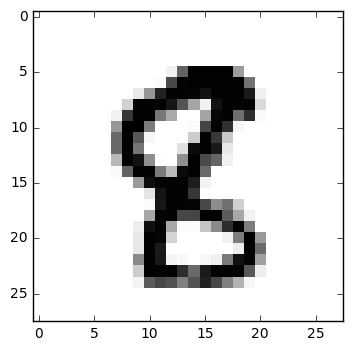

In [3]:
with tf.Session() as sess:

    # Initialize variables
    tf.global_variables_initializer().run()
    
    # Training cycle
    for step in range(1000):
        batch_xs, batch_ys = mnist.train.next_batch(100)
        sess.run(train_step, feed_dict={x: batch_xs, y_: batch_ys})

    # Calculate accuracy
    correct_prediction = tf.equal(tf.argmax(y, 1), tf.argmax(y_, 1))
    accuracy = tf.reduce_mean(tf.cast(correct_prediction, tf.float32))
    print(sess.run(accuracy, feed_dict={x: mnist.test.images, y_: mnist.test.labels}))
    
    # Get one and predict
    r = random.randint(0, mnist.test.num_examples - 1)
    print('label:', sess.run(tf.argmax(mnist.test.labels[r:r + 1], 1)))
    print('prediction:', sess.run(tf.argmax(y, 1), {x: mnist.test.images[r:r + 1]}))

    # Show the img
    plt.imshow(mnist.test.images[r:r + 1].reshape(28, 28), cmap='Greys', interpolation='nearest')
    plt.show()